In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Markdown, Image, display
P = ROOT / "data" / "processed"
F = ROOT / "docs" / "figures"
pd.options.display.float_format = "{:,.4f}".format
def table(name): return pd.read_csv(P / name)
def summary(name): return json.loads((P / name).read_text())
def fig(name): display(Image(filename=str(F / name)))
print("Simulated data. Every number below is read from executed pipeline outputs.")


Simulated data. Every number below is read from executed pipeline outputs.


# M3. Conversion models (Simulated data)

A binomial GLM (statsmodels), a monotone-constrained gradient boosted model and a naive benchmark. Splits are by time. Hyperparameters are chosen on validation only. The test period is scored once.

Target: a quote converting to a policy. No claims, frequency, severity or loss-cost model exists in this repo.

In [2]:
s = summary("m3_summary.json")
pd.DataFrame({"AUC": s["test_auc"], "log loss": s["test_log_loss"], "Brier": s["test_brier"]})

,AUC,log loss,Brier
naive,0.6530,0.2731,0.0736
glm,0.6986,0.2638,0.0722
gbm,0.6951,0.2645,0.0723


In [3]:
display(Markdown(f"GBM backend: {s['gbm_backend']}. Train {s['train_rows']:,}, validation {s['validation_rows']:,}, test {s['test_rows']:,} rows."))
table("m3_metrics__simulated_data.csv")

GBM backend: lightgbm. Train 75,358, validation 23,333, test 20,512 rows.

,split,model,roc_auc,log_loss,brier,mean_prediction,observed_rate
0,validation,naive,0.6566,0.2826,0.0770,0.0969,0.0864
1,validation,glm,0.6976,0.2747,0.0758,0.0909,0.0864
2,validation,gbm,0.6970,0.2747,0.0758,0.0905,0.0864
3,test,naive,0.6530,0.2731,0.0736,0.0971,0.0817
4,test,glm,0.6986,0.2638,0.0722,0.0813,0.0817
5,test,gbm,0.6951,0.2645,0.0723,0.0813,0.0817


In [4]:
table("m3_glm_coefficients__simulated_data.csv")

,term,coef,std_err,p_value
0,const,-3.1367,0.1321,0.0000
1,ch_direct,0.6776,0.1843,0.0002
2,ch_broker,0.4520,0.2716,0.0960
3,age_25-34,0.5048,0.0706,0.0000
4,age_35-49,0.5235,0.0677,0.0000
5,age_50-64,0.6829,0.0708,0.0000
6,age_65+,0.5648,0.0710,0.0000
7,reg_Midlands_East,0.2706,0.0344,0.0000
8,reg_North_West_Rest,0.2667,0.0331,0.0000
9,risk_medium,-0.0337,0.0282,0.2318


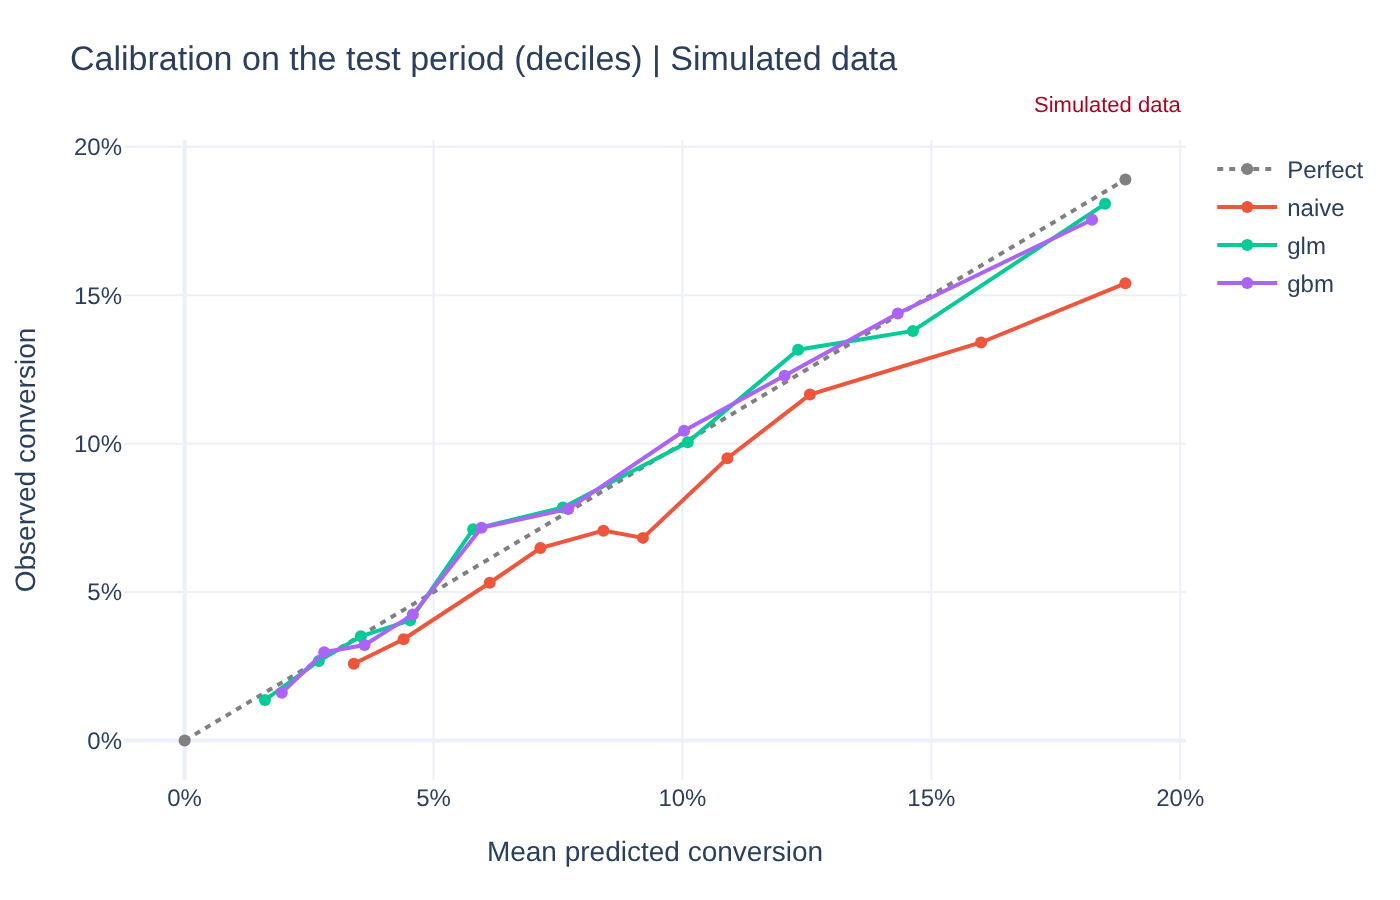

In [5]:
fig("m3_calibration__simulated_data.png")

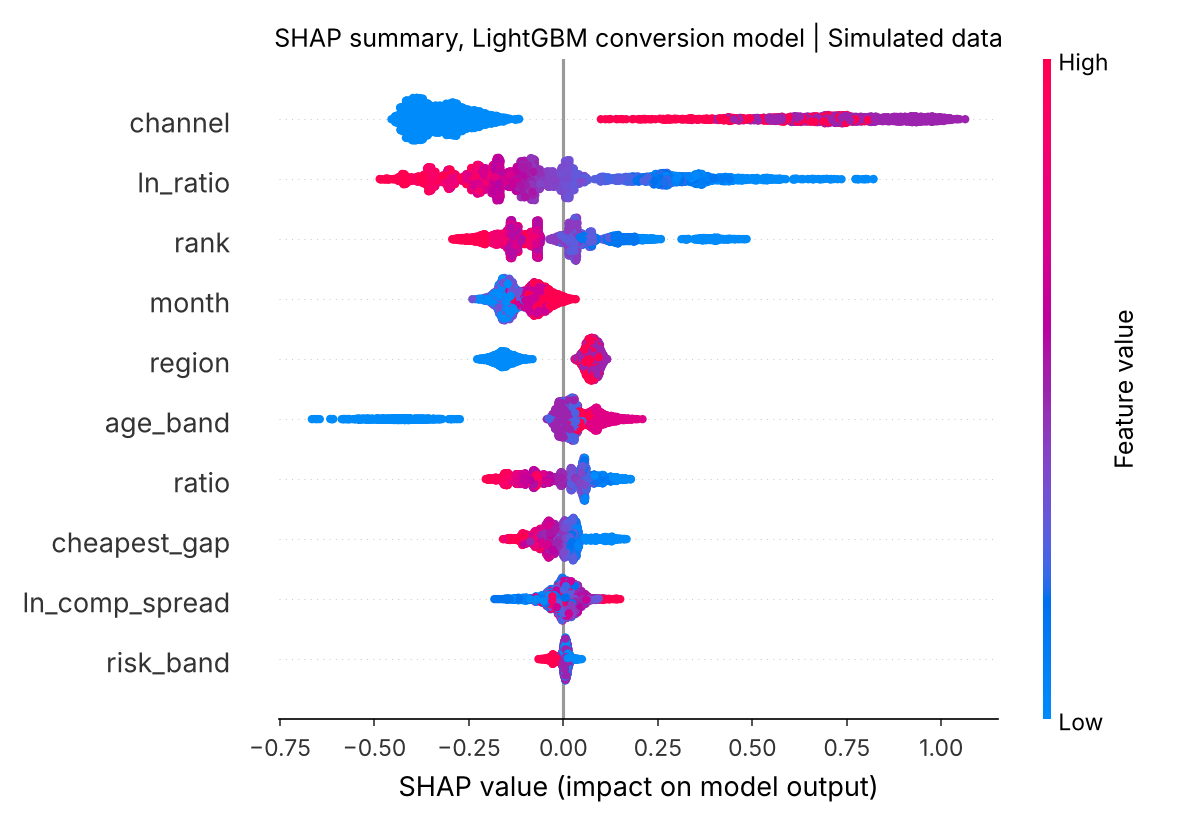

In [6]:
fig("m3_shap_beeswarm__simulated_data.png")

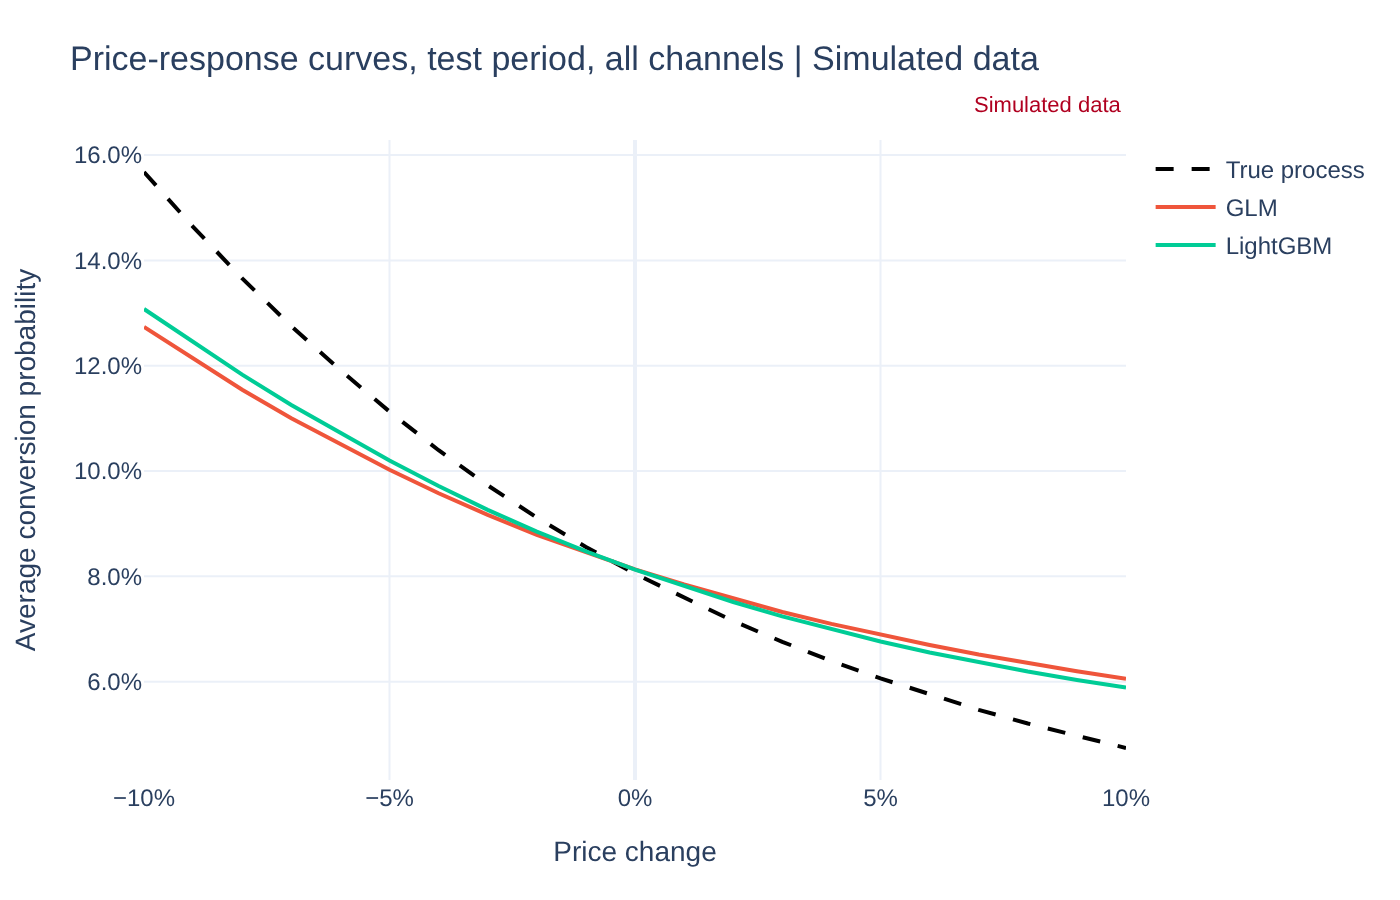

In [7]:
fig("m3_price_response__simulated_data.png")

## Limitations

- The GLM and GBM are fitted to observational quotes. Our price correlates with unobserved intent, so their price coefficients are attenuated (see M4).
- Discrimination is modest by design. Most variation in conversion is price position, which is what a real PCW market looks like, but the strength here is set by assumptions.
- Time features are used with care: month enters, row identifiers and the randomised test flag do not (see `FORBIDDEN_FEATURES`).
- The 'true' curve in the price-response chart exists only because the data is simulated.